In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))
from pipeline.notebook_utils import (
    carregar_noaa_por_tipo,
    identificar_porcoes_ativas,
    processar_ou_carregar_porcao,
    media_por_sink_raio,
    ajustar_lei_potencia,
    plotar_lei_potencia,
    plotar_varredura_r1_a_22km,
)

tipos_noaa = carregar_noaa_por_tipo()
ow_mar = tipos_noaa["Ocean water"]
print(f"Ocean water (0,02-5,0 mm, GEBCO <= 0 no mar): {len(ow_mar)} pontos")

Ocean water (0,02-5,0 mm, GEBCO <= 0 no mar): 14363 pontos


In [2]:
info, arr, label, porcoes_ativas = identificar_porcoes_ativas(ow_mar, max_r_km=50.0)

bacias_por_porcao = []
for val in porcoes_ativas:
    df_porcao = processar_ou_carregar_porcao(val, info, arr, label)
    if len(df_porcao) > 0:
        bacias_por_porcao.append(df_porcao)

df_bacias_globais = pd.concat(bacias_por_porcao, ignore_index=True)
print(f"Porcoes processadas: {len(porcoes_ativas)} | Total de bacias (100% sem corte): {len(df_bacias_globais)}")

Porcoes processadas: 1061 | Total de bacias (100% sem corte): 179718


In [3]:
pareados_por_r = {}
linhas_r = []
for r_km in range(1, 23):
    df_r = media_por_sink_raio(df_bacias_globais, ow_mar, r_km=r_km)
    pareados_por_r[r_km] = df_r
    st_u = ajustar_lei_potencia(df_r, "urban_population", "mp_mean")
    st_fu = ajustar_lei_potencia(df_r, "urban_population", "flux")
    st_t = ajustar_lei_potencia(df_r, "total_population", "mp_mean")
    st_ft = ajustar_lei_potencia(df_r, "total_population", "flux")
    linhas_r.append({
        "R_km": r_km,
        "N_urb": st_u["N"],
        "beta_urb": st_u["beta"],
        "R2_urb_pct": st_u["r2_pct"],
        "R2_flux_urb_pct": st_fu["r2_pct"],
        "N_tot": st_t["N"],
        "beta_tot": st_t["beta"],
        "R2_tot_pct": st_t["r2_pct"],
        "R2_bins_tot_pct": st_t["r2_bins_pct"],
        "R2_flux_tot_pct": st_ft["r2_pct"],
    })

df_varredura = pd.DataFrame(linhas_r)
print(df_varredura.round(2).to_string(index=False))

 R_km  N_urb  beta_urb  R2_urb_pct  R2_flux_urb_pct  N_tot  beta_tot  R2_tot_pct  R2_bins_tot_pct  R2_flux_tot_pct
    1      0       NaN         NaN              NaN      0       NaN         NaN              NaN              NaN
    2      9      0.75       25.49            35.04     29      0.44       27.70            60.11            37.54
    3     74      0.15        0.86             7.58    193      0.40       14.97            73.43            28.05
    4    157      0.36        5.31            15.08    438      0.38       14.57            80.95            27.71
    5    254      0.49       10.62            24.24    754      0.35       13.25            96.38            26.05
    6    338      0.48       10.29            22.70   1113      0.33       13.58            94.77            26.88
    7    425      0.45        9.32            20.45   1507      0.32       12.89            92.30            26.00
    8    511      0.41        7.77            18.46   1922      0.33       13.51

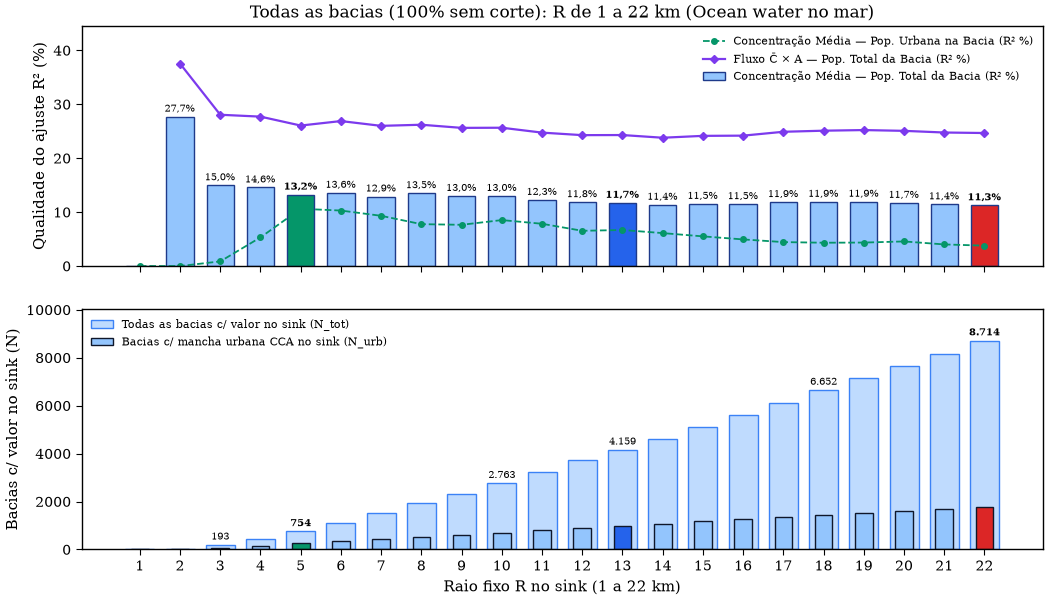

In [4]:
plotar_varredura_r1_a_22km(df_varredura)

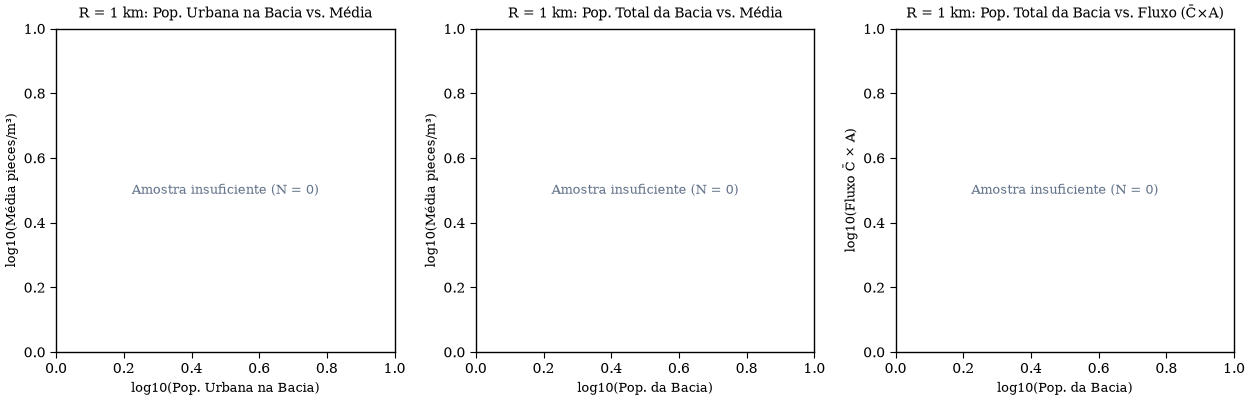

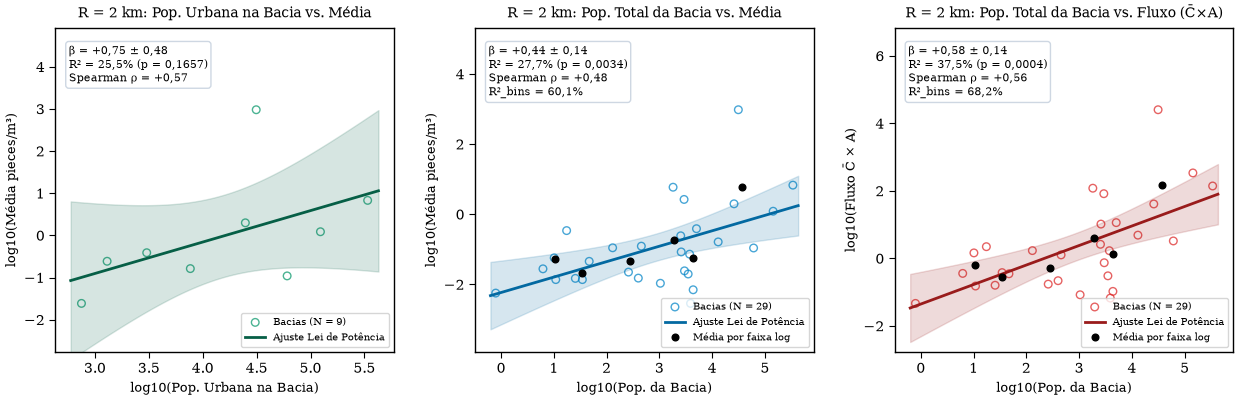

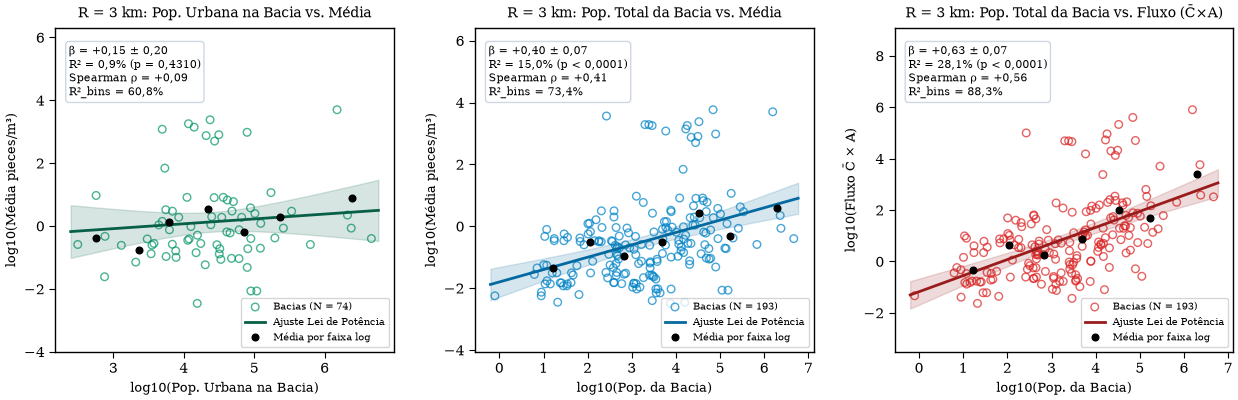

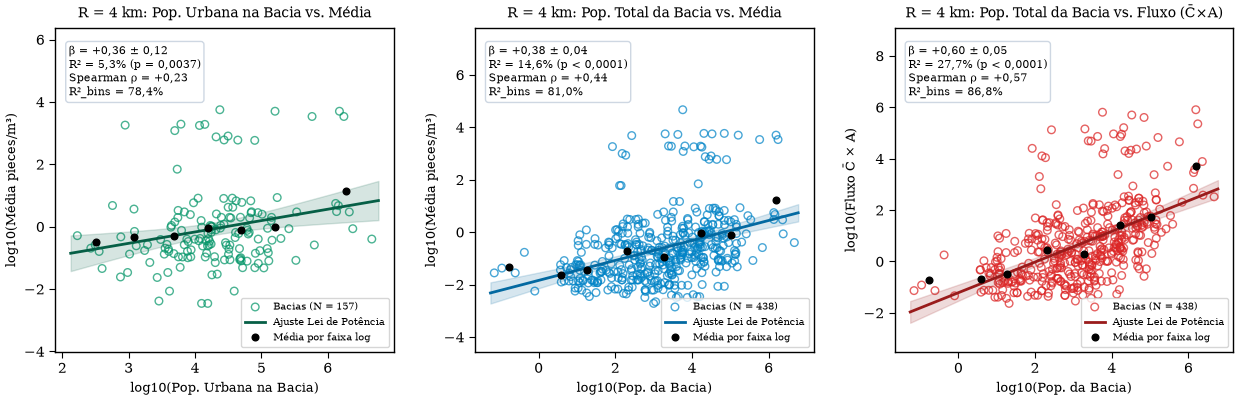

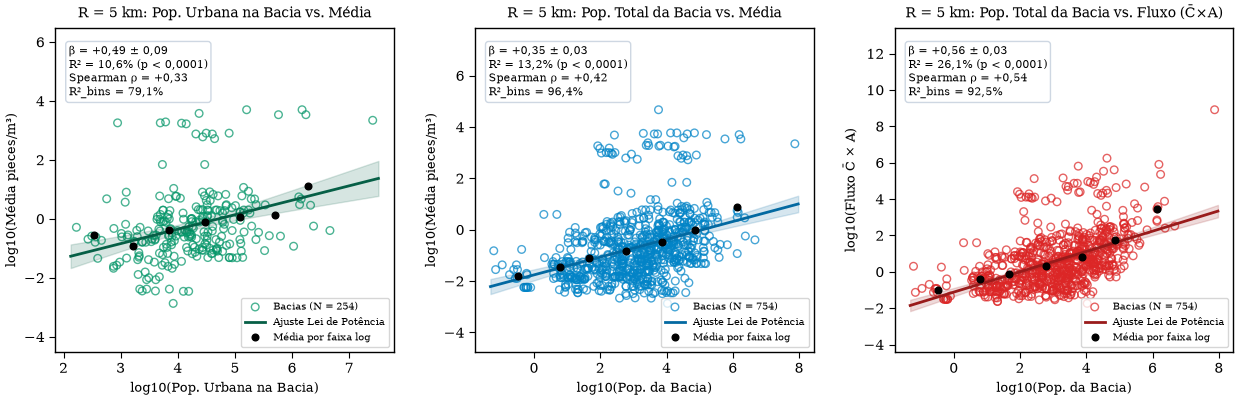

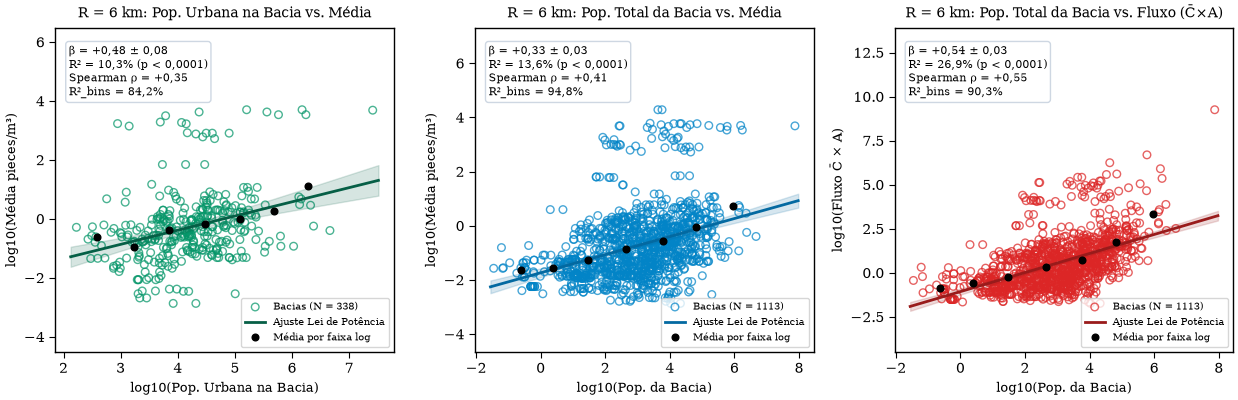

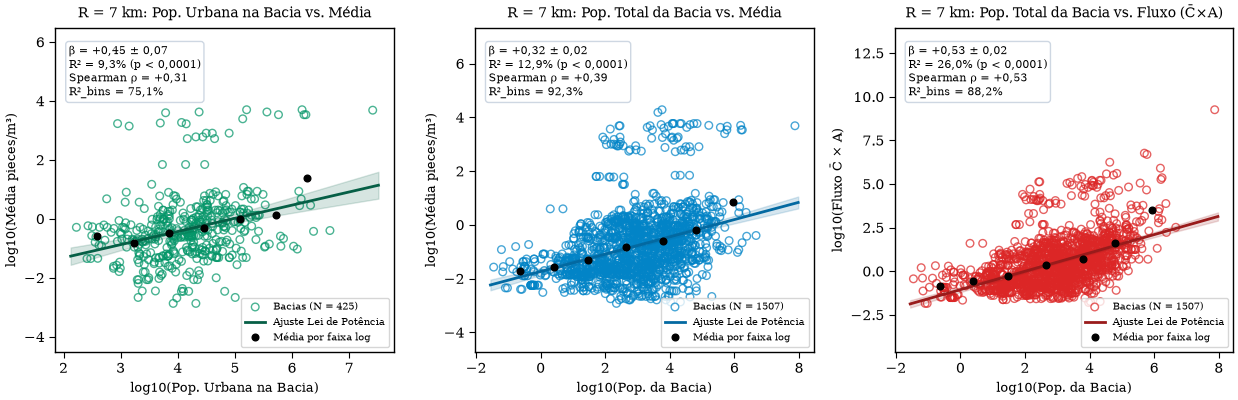

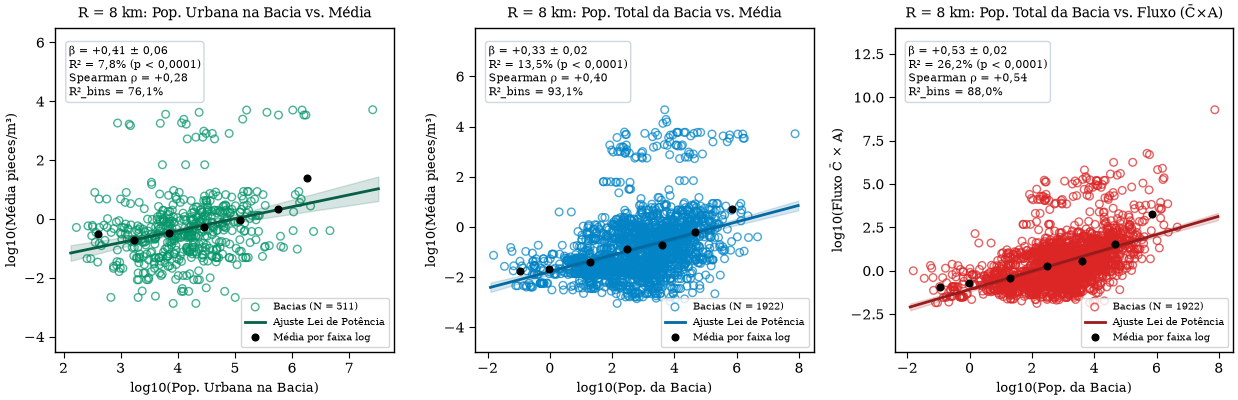

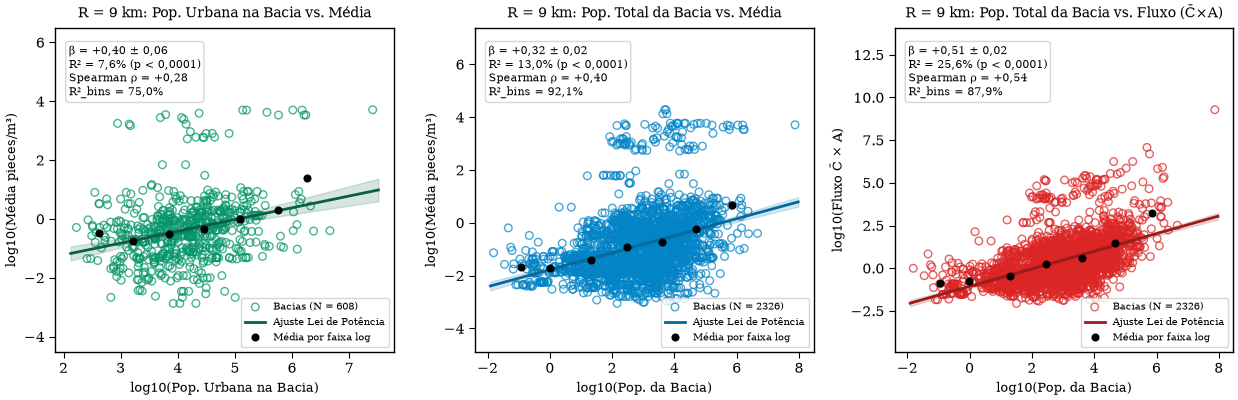

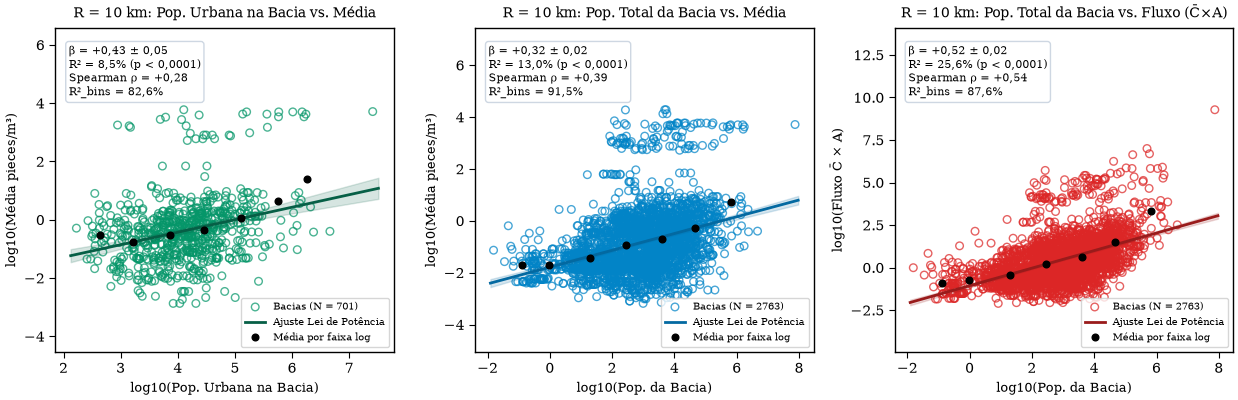

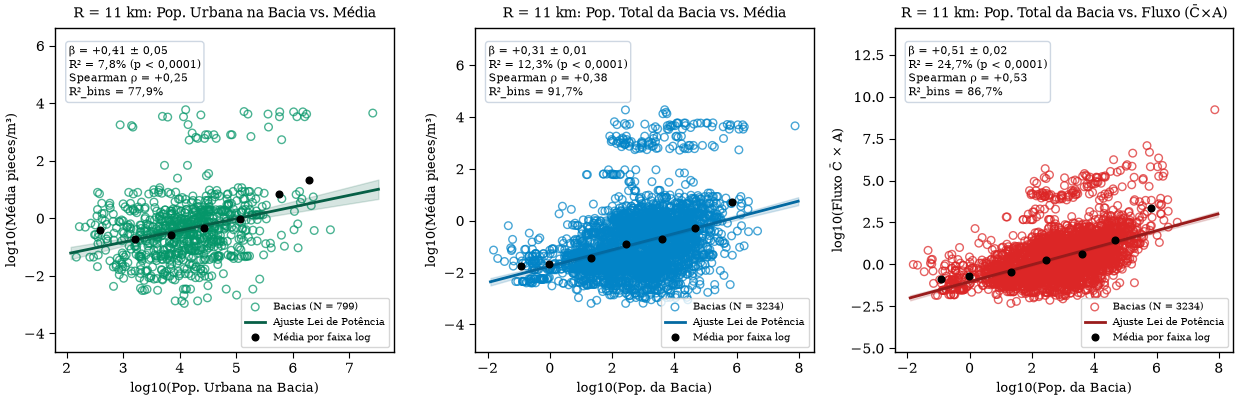

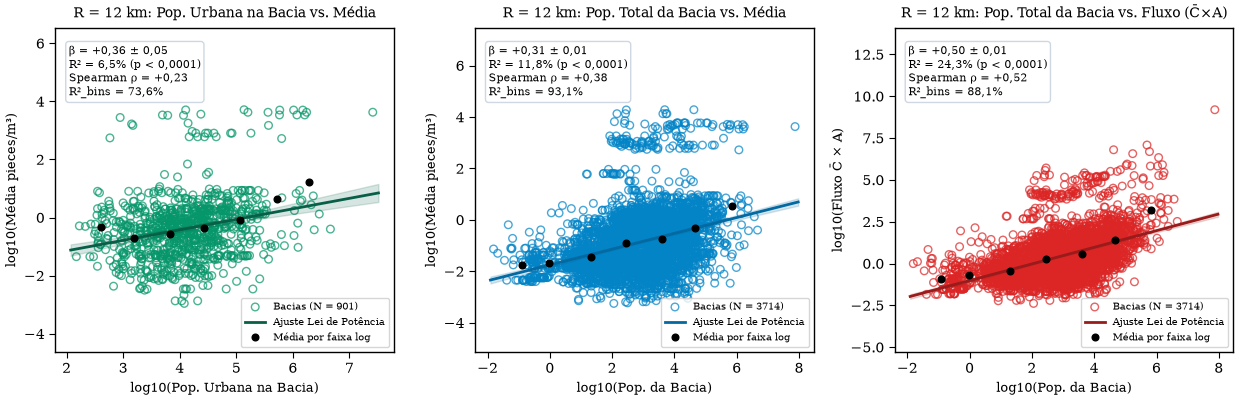

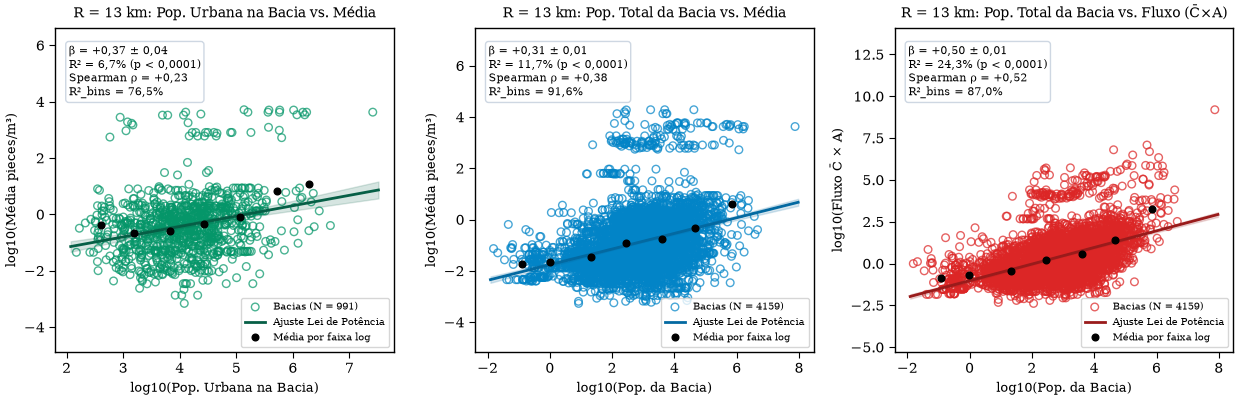

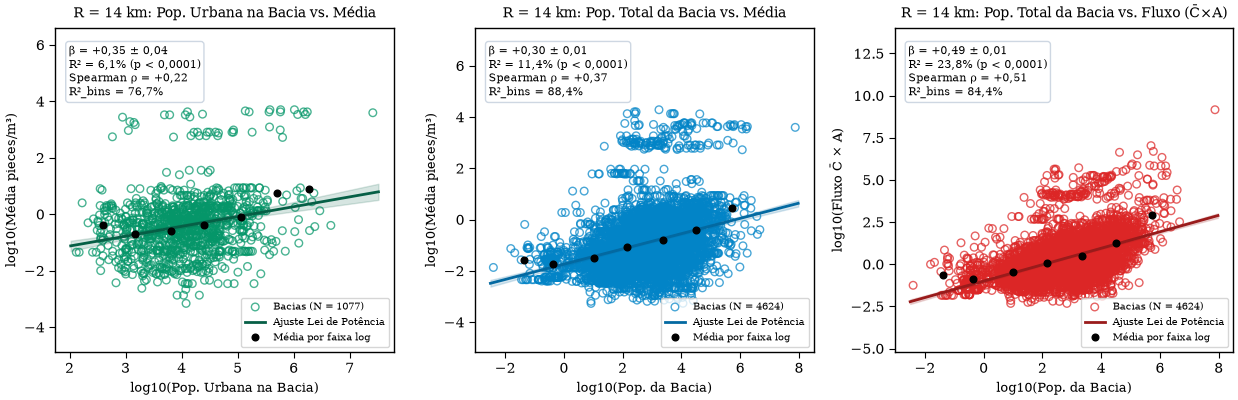

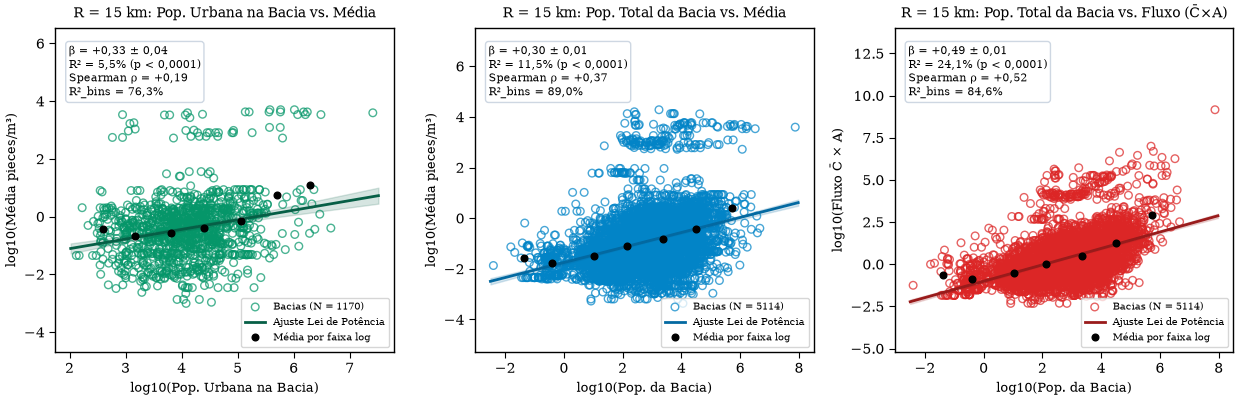

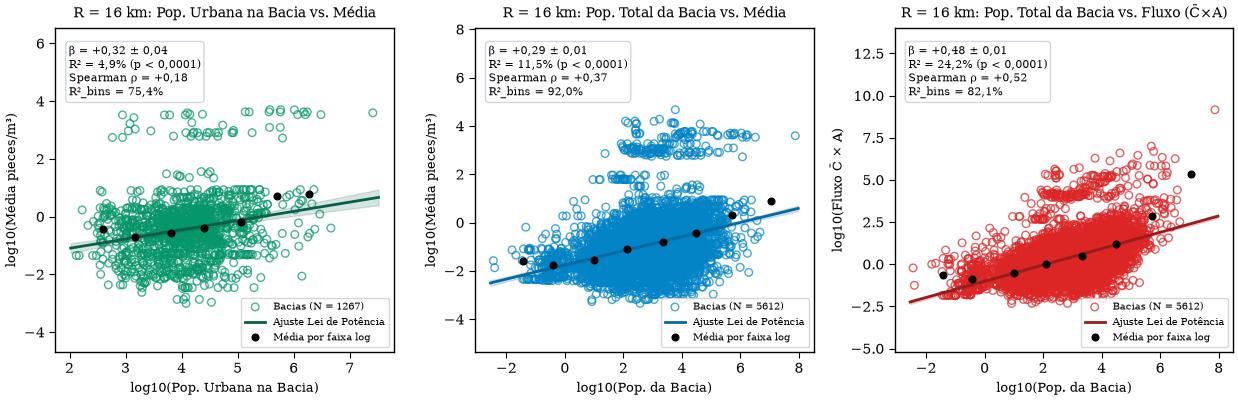

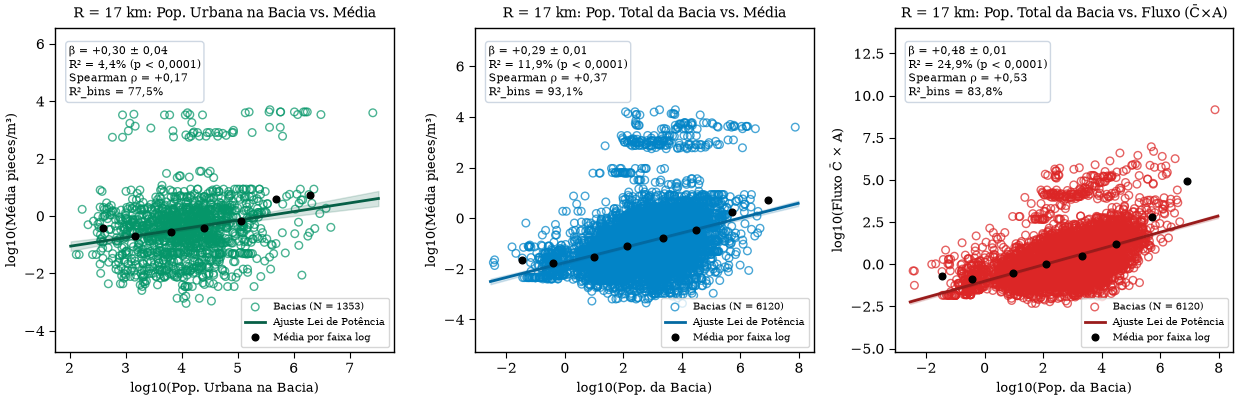

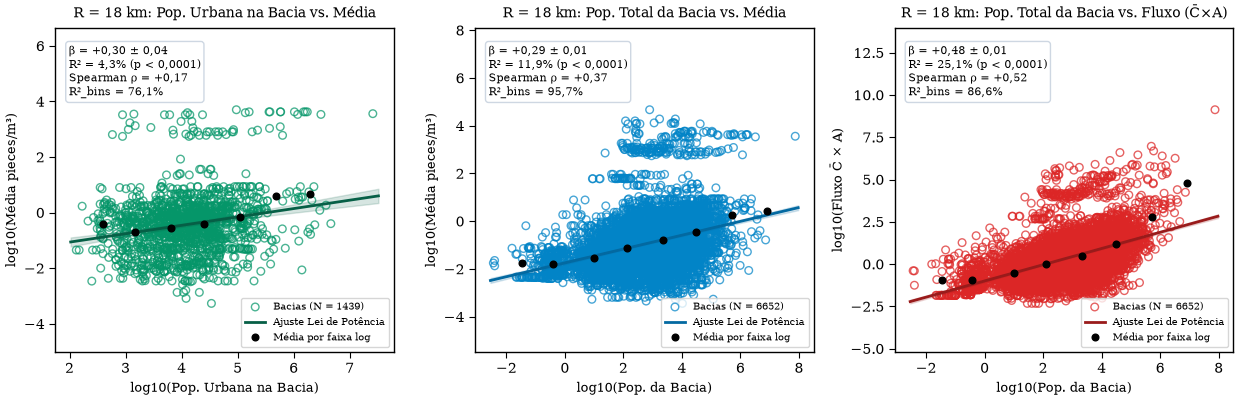

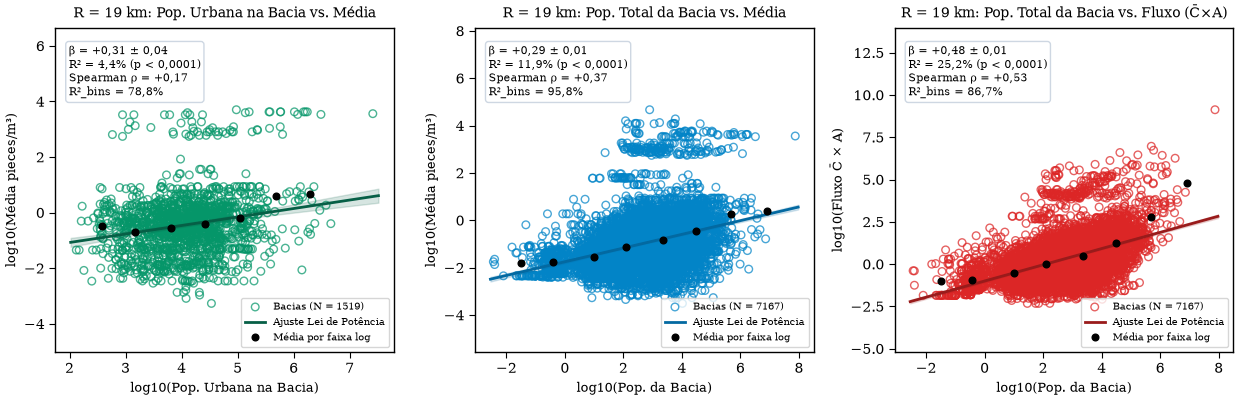

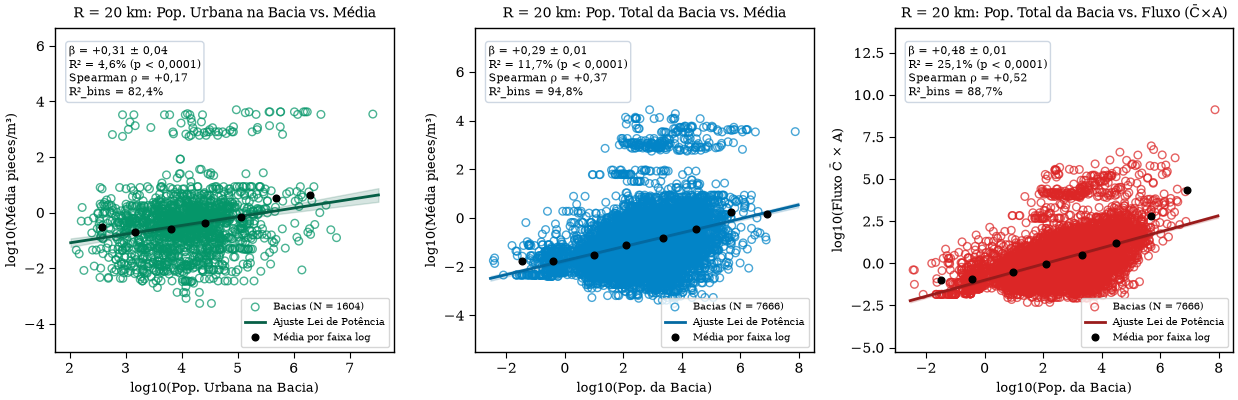

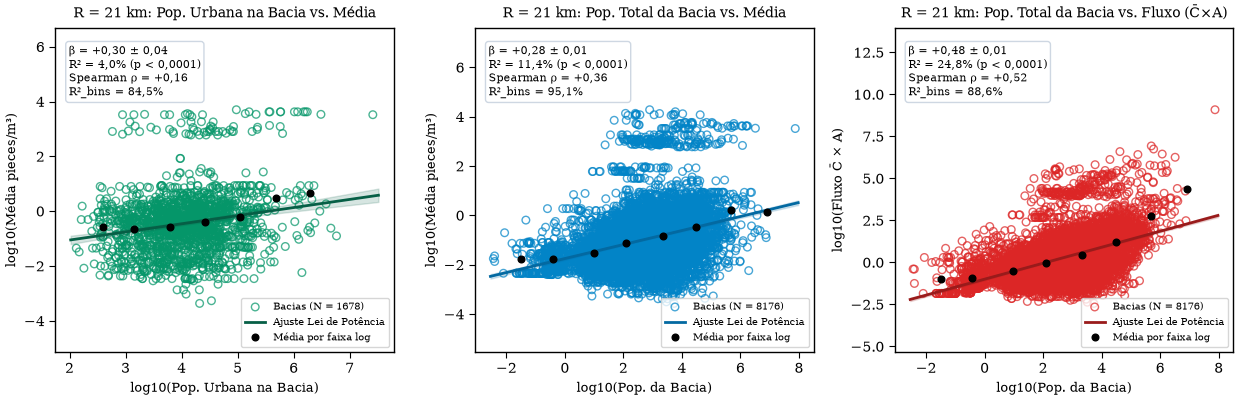

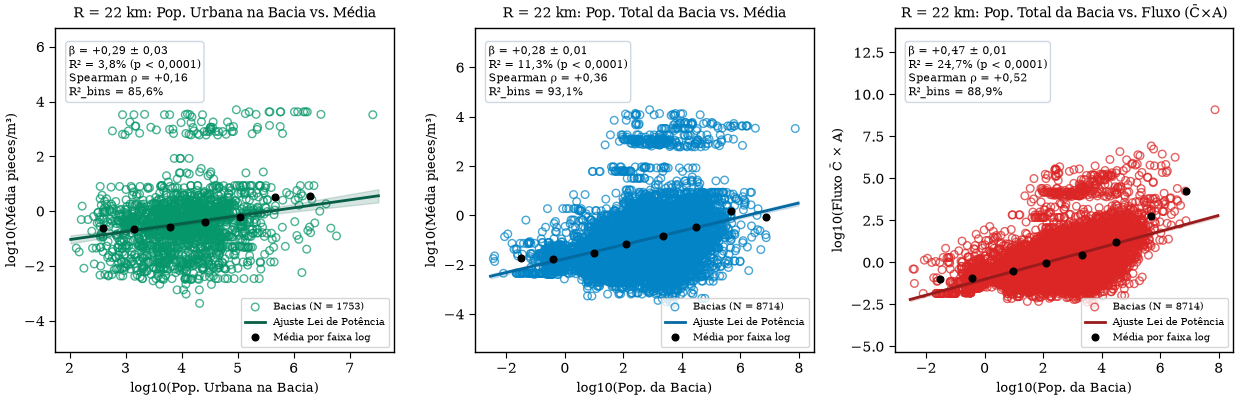

In [5]:
for r_km in range(1, 23):
    df_r = pareados_por_r[r_km]
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15.2, 4.2), gridspec_kw={"wspace": 0.24})
    plotar_lei_potencia(ax1, df_r, "urban_population", "mp_mean", f"R = {r_km} km: Pop. Urbana na Bacia vs. Média", "log10(Pop. Urbana na Bacia)", "log10(Média pieces/m³)", "#059669", "#065f46")
    plotar_lei_potencia(ax2, df_r, "total_population", "mp_mean", f"R = {r_km} km: Pop. Total da Bacia vs. Média", "log10(Pop. da Bacia)", "log10(Média pieces/m³)", "#0284c7", "#0369a1")
    plotar_lei_potencia(ax3, df_r, "total_population", "flux", f"R = {r_km} km: Pop. Total da Bacia vs. Fluxo (C̄×A)", "log10(Pop. da Bacia)", "log10(Fluxo C̄ × A)", "#dc2626", "#991b1b")
    plt.show()